# Kiểm tra model phát hiện vùng che logo / nhãn

Chọn ảnh theo đường dẫn, chọn model, chạy ô 3 là ra kết quả.

| `MODEL` | Model | Đầu ra |
|---|---|---|
| `"probe"` | Probe DINOv2 theo mảnh (`work/probe.pt`, lượt 6) | bản đồ nhiệt + khung = vùng có điểm ≥ ngưỡng |
| `"rfdetr"` | RF-DETR small đã fine-tune (`work/rfdetr_out/checkpoint_best_total.pth`) | khung + điểm |
| `"ket_hop"` | RF-DETR đề xuất khung, probe kiểm lại: giữ khung nếu điểm probe trong khung ≥ `NGUONG_PROBE_KIEM` | khung + 2 điểm |

Đo trên ảnh thật (13–14/11/2026): `ket_hop` ít báo thừa nhất (ảnh shop sạch: 7 khung thừa / 150 ảnh, so với 12 của probe và 18 của RF-DETR), bắt tương đương.
Kết quả chỉ là **tín hiệu sàng lọc** "có dấu hiệu che logo/nhãn", không phải kết luận.

Kernel: `logo-obstruct (.venv)`.

In [8]:
# ===================== THAM SỐ: sửa ở đây =====================
MODEL = "ket_hop"            # "probe" | "rfdetr" | "ket_hop"

# Đường dẫn ảnh: file hoặc thư mục (lấy mọi ảnh trong thư mục). Có thể ghi nhiều đường dẫn.
DUONG_DAN = [
    r"D:\Code\logo-obstruct-detection\test_model\vn-11134207-7ra0g-mah62kxdmfvc94.webp",
]
CHON_BANG_HOP_THOAI = False  # True: mở hộp chọn file của Windows thay cho DUONG_DAN

NGUONG_PROBE = 0.94          # MODEL="probe": vùng có điểm ≥ ngưỡng thì báo (chọn trên ảnh shop thật)
NGUONG_RFDETR = 0.3          # MODEL="rfdetr" / "ket_hop": khung RF-DETR có điểm ≥ ngưỡng
NGUONG_PROBE_KIEM = 0.9      # MODEL="ket_hop": giữ khung RF-DETR nếu điểm probe lớn nhất trong khung ≥ ngưỡng
HIEN_KHUNG_BI_LOAI = True    # MODEL="ket_hop": vẽ cả khung RF-DETR bị probe loại (nét xám)

LUU_KET_QUA = False          # True: lưu hình + JSON vào THU_MUC_KET_QUA
THU_MUC_KET_QUA = r"D:\Code\logo-obstruct-detection\work\ket_qua_test"
# ===============================================================

In [2]:
import json
import math
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from matplotlib.patches import Patch, Rectangle
from PIL import Image

ROOT = Path(r"D:\Code\logo-obstruct-detection")
WORK = ROOT / "work"
DINO_DIR = Path(r"D:\Code\TH.AntiFakeExt\poc\models\dinov2-base")   # chỉ đọc
PROBE_PT = WORK / "probe.pt"
RFDETR_CKPT = WORK / "rfdetr_out" / "checkpoint_best_total.pth"
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32
ANH = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
MAX_SIDE = 1024              # như lúc train
MIN_AREA = 0.0001            # vùng nhỏ hơn 0,01% ảnh thì bỏ (nhiễu)
assert MODEL in ("probe", "rfdetr", "ket_hop"), "MODEL phải là probe, rfdetr hoặc ket_hop"

# ---------- probe DINOv2 ----------
SIZE, PATCH, LAYERS = 518, 14, (4, 8, 12)
G = SIZE // PATCH
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)


class Probe(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
        self.register_buffer("mu", torch.zeros(d)); self.register_buffer("sd", torch.ones(d))

    def forward(self, x):
        return self.net((x.float() - self.mu) / self.sd).squeeze(-1)


_M = {}


def nap_model():
    t0 = time.time()
    if MODEL in ("probe", "ket_hop") and "dino" not in _M:
        from transformers import AutoModel
        _M["dino"] = AutoModel.from_pretrained(DINO_DIR, dtype=DT).to(DEV).eval()
        sd = torch.load(PROBE_PT, map_location=DEV)
        p = Probe(sd["mu"].numel()).to(DEV); p.load_state_dict(sd); p.eval()
        _M["probe"] = p
    if MODEL in ("rfdetr", "ket_hop") and "rfdetr" not in _M:
        from rfdetr import RFDETRSmall
        _M["rfdetr"] = RFDETRSmall(pretrain_weights=str(RFDETR_CKPT))
    print(f"Đã nạp model cho MODEL = '{MODEL}' ({time.time() - t0:.0f} s, {DEV})")


@torch.inference_mode()
def ban_do_probe(img):
    """Xác suất 'bị che' cho từng điểm ảnh (0..1), cùng cỡ img."""
    h, w = img.shape[:2]; s = SIZE / max(h, w); nh, nw = round(h * s), round(w * s)
    lb = np.zeros((SIZE, SIZE, 3), np.uint8); lb[:nh, :nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy((lb.astype(np.float32) / 255 - MEAN) / STD).permute(2, 0, 1)[None].to(DEV, DT)
    hs = _M["dino"](pixel_values=x, output_hidden_states=True).hidden_states
    q = _M["probe"](torch.cat([hs[l][:, 1:] for l in LAYERS], -1)[0]).sigmoid().float().cpu().numpy().reshape(G, G)
    v = np.zeros_like(q, bool); v[:math.ceil(nh / PATCH), :math.ceil(nw / PATCH)] = True; q[~v] = 0
    return cv2.resize(cv2.resize(q, (SIZE, SIZE))[:nh, :nw], (w, h))


def khung_tu_ban_do(full, thr):
    n, lab, st, _ = cv2.connectedComponentsWithStats((full >= thr).astype(np.uint8))
    H, W = full.shape
    return [{"bbox": [int(st[i][0]), int(st[i][1]), int(st[i][0] + st[i][2]), int(st[i][1] + st[i][3])],
             "diem_probe": round(float(full[lab == i].max()), 3)}
            for i in range(1, n) if st[i][4] >= MIN_AREA * H * W]


def _iou(a, b):
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1])); i = iw * ih
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-9)


def khung_rfdetr(img, thr, nms_iou=0.5):
    """Khung RF-DETR điểm ≥ thr; gộp khung gần trùng (IoU ≥ nms_iou), giữ khung điểm cao hơn."""
    d = _M["rfdetr"].predict(Image.fromarray(img), threshold=thr)
    ks = sorted(({"bbox": [round(float(v), 1) for v in b], "diem_rfdetr": round(float(s), 3)} for b, s in zip(d.xyxy, d.confidence)),
                key=lambda k: -k["diem_rfdetr"])
    giu = []
    for k in ks:
        if all(_iou(k["bbox"], g["bbox"]) < nms_iou for g in giu):
            giu.append(k)
    return giu


# ---------- chọn ảnh ----------
def chon_file():
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    fs = filedialog.askopenfilenames(title="Chọn ảnh để kiểm tra",
                                     filetypes=[("Ảnh", " ".join("*" + e for e in ANH)), ("Tất cả", "*.*")])
    root.destroy()
    return list(fs)


def danh_sach_anh():
    src = chon_file() if CHON_BANG_HOP_THOAI else DUONG_DAN
    out = []
    for s in src:
        p = Path(str(s).strip().strip('"'))
        if p.is_dir():
            out += sorted(q for q in p.iterdir() if q.suffix.lower() in ANH)
        elif p.is_file():
            out.append(p)
        else:
            print(f"Không tìm thấy: {p}")
    return out


# ---------- phân tích một ảnh ----------
def phan_tich(path):
    im = Image.open(path).convert("RGB"); W0, H0 = im.size
    im.thumbnail((MAX_SIDE, MAX_SIDE)); img = np.asarray(im)
    heat, giu, loai = None, [], []
    if MODEL in ("probe", "ket_hop"):
        heat = ban_do_probe(img)
    if MODEL == "probe":
        giu = khung_tu_ban_do(heat, NGUONG_PROBE)
    else:
        for k in khung_rfdetr(img, NGUONG_RFDETR):
            if MODEL == "rfdetr":
                giu.append(k); continue
            x0, y0, x1, y1 = (int(max(0, k["bbox"][0])), int(max(0, k["bbox"][1])), int(k["bbox"][2]) + 1, int(k["bbox"][3]) + 1)
            k["diem_probe"] = round(float(heat[y0:y1, x0:x1].max()), 3) if heat[y0:y1, x0:x1].size else 0.0
            (giu if k["diem_probe"] >= NGUONG_PROBE_KIEM else loai).append(k)
    key = "diem_probe" if MODEL == "probe" else "diem_rfdetr"
    giu.sort(key=lambda r: -r[key])
    s = W0 / img.shape[1]   # khung trả về theo cỡ ảnh gốc
    for r in giu + loai:
        r["bbox_goc"] = [round(v * s, 1) for v in r["bbox"]]
    return img, heat, giu, loai, {"anh": str(path), "model": MODEL, "co_dau_hieu_che": bool(giu), "so_vung": len(giu),
                                  "vung": [{k: v for k, v in r.items() if k != "bbox"} for r in giu],
                                  "khung_bi_loai": [{k: v for k, v in r.items() if k != "bbox"} for r in loai]}


def ve(path, img, heat, giu, loai, kq):
    H, W = img.shape[:2]
    fig, ax = plt.subplots(1, 2, figsize=(13, 6.2 * H / W + 0.8), gridspec_kw={"width_ratios": [1, 1.08]})
    ax[0].imshow(img); ax[0].set_title("Ảnh gốc", fontsize=10)
    ax[1].imshow(img)
    if heat is not None:   # lớp màu: xác suất 'bị che' của probe, thang jet 0 (xanh) → 1 (đỏ)
        hm = ax[1].imshow(heat, cmap="jet", vmin=0, vmax=1, alpha=0.45)
        cb = fig.colorbar(hm, ax=ax[1], fraction=0.046, pad=0.02); cb.set_label("xác suất bị che (probe)", fontsize=8)
    lw = max(1.5, W / 400)
    if MODEL == "ket_hop" and HIEN_KHUNG_BI_LOAI:
        for r in loai:
            b = r["bbox"]
            ax[1].add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="0.6", lw=lw, ls="--"))
    for k, r in enumerate(giu, 1):
        b = r["bbox"]
        ax[1].add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="magenta", lw=lw * 1.3))
        nhan = (f"{k}: {r['diem_probe']:.2f}" if MODEL == "probe" else f"{k}: {r['diem_rfdetr']:.2f}"
                + (f" / {r['diem_probe']:.2f}" if MODEL == "ket_hop" else ""))
        ax[1].text(b[0], b[1] - 3, nhan, color="white", fontsize=8, va="bottom",
                   bbox=dict(facecolor="magenta", alpha=0.8, pad=1, lw=0))
    chu = [Patch(fc="none", ec="magenta", lw=2, label="vùng nghi bị che")]
    if MODEL == "ket_hop" and HIEN_KHUNG_BI_LOAI and loai:
        chu.append(Patch(fc="none", ec="0.6", lw=2, ls="--", label="khung RF-DETR bị probe loại"))
    ax[1].legend(handles=chu, loc="lower right", fontsize=8, framealpha=0.85)
    nguong = {"probe": f"probe ≥ {NGUONG_PROBE}", "rfdetr": f"RF-DETR ≥ {NGUONG_RFDETR}",
              "ket_hop": f"RF-DETR ≥ {NGUONG_RFDETR} và probe ≥ {NGUONG_PROBE_KIEM}"}[MODEL]
    ax[1].set_title(("CÓ DẤU HIỆU CHE: " + str(len(giu)) + " vùng" if giu else "Không thấy dấu hiệu che") + f"  ({nguong})",
                    fontsize=10, color="crimson" if giu else "green")
    for a in ax:
        a.axis("off")
    name = str(path)
    fig.suptitle(f"[{MODEL}] " + (name if len(name) < 100 else "…" + name[-98:]), fontsize=9)
    plt.tight_layout()
    if LUU_KET_QUA:
        out = Path(THU_MUC_KET_QUA); out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / f"{Path(path).stem}_{MODEL}.jpg", dpi=110)
        (out / f"{Path(path).stem}_{MODEL}.json").write_text(json.dumps(kq, ensure_ascii=False, indent=1), encoding="utf-8")
    plt.show()
    if giu:
        diem = "điểm probe" if MODEL == "probe" else ("điểm RF-DETR / probe" if MODEL == "ket_hop" else "điểm RF-DETR")
        print(f"  {'vùng':>4}  {diem:<22} khung (ảnh gốc, x0 y0 x1 y1)")
        for k, r in enumerate(giu, 1):
            d = (f"{r['diem_probe']:.3f}" if MODEL == "probe" else f"{r['diem_rfdetr']:.3f}"
                 + (f" / {r['diem_probe']:.3f}" if MODEL == "ket_hop" else ""))
            print(f"  {k:>4}  {d:<22} {r['bbox_goc']}")
    if loai:
        print(f"  ({len(loai)} khung RF-DETR bị probe loại)")


nap_model()

d:\Code\logo-obstruct-detection\.venv\Lib\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
[2026-11-16 09:28:01] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-16 09:28:01] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-16 09:28:01] [INFO] rf-detr - Loading pretrain weights


[2026-11-16 09:28:01] [WARNING] rf-detr - Reinitializing detection head with 1 classes based on pretrained weights, configured for 90.


Đã nạp model cho MODEL = 'ket_hop' (10 s, cuda)


## Chạy
Sửa tham số ở ô 1, rồi chạy lại **ô 1 và ô này**. Đổi `MODEL` thì chạy lại cả ô 2 để nạp model.

1 ảnh · MODEL = 'ket_hop'


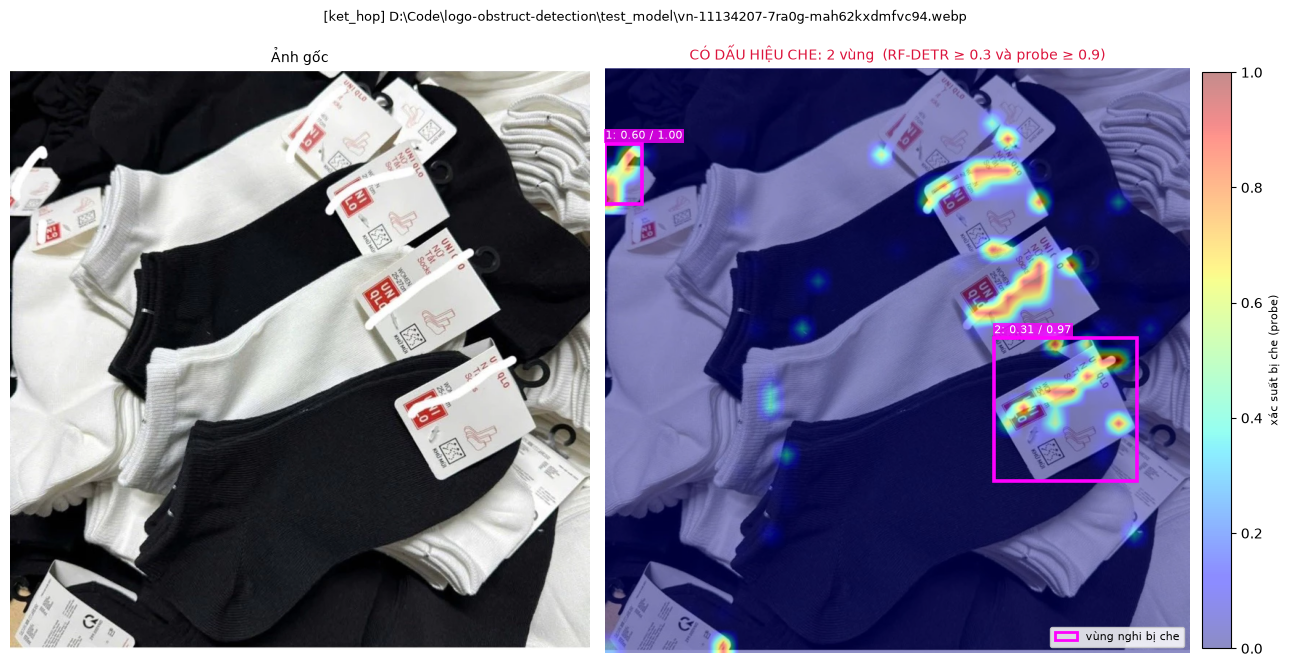

  vùng  điểm RF-DETR / probe   khung (ảnh gốc, x0 y0 x1 y1)
     1  0.598 / 1.000          [0.4, 103.0, 50.6, 185.6]
     2  0.311 / 0.970          [532.1, 369.1, 727.2, 564.9]

Tổng: 1/1 ảnh có dấu hiệu che


In [9]:
ds = danh_sach_anh()
print(f"{len(ds)} ảnh · MODEL = '{MODEL}'")
tong = []
for p in ds:
    try:
        img, heat, giu, loai, kq = phan_tich(p)
        ve(p, img, heat, giu, loai, kq)
        tong.append(kq)
    except Exception as e:   # file hỏng / không phải ảnh
        print(f"Lỗi với {p}: {type(e).__name__}: {e}")
print(f"\nTổng: {sum(k['co_dau_hieu_che'] for k in tong)}/{len(tong)} ảnh có dấu hiệu che"
      + (f" · đã lưu vào {THU_MUC_KET_QUA}" if LUU_KET_QUA else ""))